In [12]:
import numpy as np
import matplotlib.pyplot as plt
import datetime
import yfinance as yf
import pandas as pd
from scipy.optimize import minimize
import random
from pathlib import Path

from utils import (
    get_historical_data,
    get_market_caps,
    calc_ceiling_performance,
    calc_floor_performance,
    get_sigma_aug,
)

df = pd.read_excel("S&P 500.xlsx")
UNIVERSE = list(df["Symbol"])

UNIVERSE = [s for s in UNIVERSE if s not in ["BF.B", "BRK.B"]][:50]
START_DATE = datetime.date(2023, 6, 29)
END_DATE = datetime.date(2026, 6, 29)
BENCHMARK = "SPY"
N = 50


In [ ]:
def get_initial_state(N: int, K: int | None = None):
    K = N // 3 if K is None else K
    return set(random.sample(range(N), K))


def propose_move(
    selected: set,
    N: int,
    p_add: float = 0.33,
    p_swap: float = 0.34,
    p_remove: float = 0.33
) -> set:
    chance = random.random()
    new_set = selected.copy()

    # guards
    if len(selected) == 1:
        p_remove = 0
    if len(selected) == N:
        p_add = 0

    if chance < p_add:
        candidates = tuple(set(range(N)) - selected)
        new_set.add(random.choice(candidates))
    elif chance < p_add + p_remove:
        new_set.remove(random.choice(tuple(selected)))
    else:
        candidates = tuple(set(range(N)) - selected)
        if not candidates:  # size == N, can't swap, fall back to remove
            new_set.remove(random.choice(tuple(selected)))
        else:
            to_remove = random.choice(tuple(selected))
            new_set.remove(to_remove)
            new_set.add(random.choice(candidates))

    return new_set

    

def ScoreSelection(selected_indices: set, sigma_aug: np.ndarray, cost_factor: float = 1e-6, w0 = None) -> tuple[float, np.ndarray]:
    # Make Cov matrix smaller for speedier calcs
    bench_idx = sigma_aug.shape[0] - 1
    sub_idx = sorted(selected_indices) + [bench_idx]
    submatrix = sigma_aug[np.ix_(sub_idx, sub_idx)]

    def ScaledTE(weights: np.ndarray):
        return 1e6 * RelativeTrackingError(weights, submatrix)
    
    K = len(selected_indices)
    
    w0 = np.ones(K) / K if w0 is None else w0

    res = minimize(
        ScaledTE,
        w0,
        method='SLSQP',
        bounds=[(0, None)] * K,
        constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
    )

    if res.success:
        return (res.fun / 1e6) + (K * cost_factor), res.x
    else:
        print(f"Failed to resolve! {selected_indices=}")
        return float('inf'), np.zeros(K)
    

def adjust_weights(weights: np.ndarray, state: set, new_state: set):
    # Map stock index → its current weight
    weight_map = {stock: w for stock, w in zip(sorted(state), weights)}
    
    # Drop removed stocks, add new ones with weight 0
    for stock in (state - new_state):
        del weight_map[stock]
    for stock in (new_state - state):
        weight_map[stock] = 0.0
    
    # Return in sorted order, renormalised
    weights = np.array([weight_map[s] for s in sorted(new_state)])
    return weights / weights.sum() if weights.sum() > 0 else np.ones(len(new_state)) / len(new_state)



In [ ]:



def RunSimulatedAnnealing(
    N: int,  # Size of universe
    sigma_aug: np.ndarray,
    n_steps: int = 4_000,  # Loops till termination
    T_init: float = 8.6e-6,  # Initial "temp"
    alpha: float = 0.999,  # Decay rate of temp
    K: int | None = None,  # Desired holding size
    cost_factor: float = 1e-6,  # Scale factor for cost of additional holding
    p_add: float = 0.33,  # Probability next move adds an index
    p_swap: float = 0.34,  # Probability next move swaps an index
    p_remove: float = 0.33,  # Probability next move removes an index
) -> tuple[set, float, dict]:
    # If set K change probabilities
    if K:
        p_add = 0
        p_remove = 0
        p_swap = 1
    
    assert abs(p_add + p_swap + p_remove - 1) < 1e-9, "Move probabilities must sum to one"

    # Setup initial conditions
    state = get_initial_state(N, K)
    score, current_weights = ScoreSelection(state, sigma_aug, cost_factor)
    T = T_init
    best_state, best_score = state, score

    # Setup analytics
    score_history = [best_score]
    acceptance_history = []
    accepted = 0
    total = 0

    for step in range(n_steps):
        new_state = propose_move(state, N, p_add, p_swap, p_remove)
        w0 = adjust_weights(current_weights, state, new_state)
        new_score, new_weights = ScoreSelection(new_state, sigma_aug, cost_factor, w0=w0)

        delta = new_score - score
        
        # If new score is better (or randomly)
        if delta < 0 or random.random() < np.exp(-delta / T):
            state, score = new_state, new_score
            current_weights = new_weights
            accepted += 1
            score_history.append(score)
            # Update best score if it is
            if score < best_score:
                best_state, best_score = state, score

        total += 1
        
        if total == 50:
            acceptance_history.append(accepted / total)
            accepted = 0
            total = 0
        T *= alpha

    return best_state, best_score, {
        "scoreHistory": score_history,
        "acceptanceHistory": acceptance_history,
    }
    



[*********************100%***********************]  1 of 1 completed
/var/folders/by/bfs1t05x37z83kbrvgrxgzjm0000gn/T/ipykernel_12397/4235573837.py:45: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  return pd.concat([daily_returns, spy_data], axis=1).dropna().cov().to_numpy()


In [ ]:
N = len(UNIVERSE)
SIGMA_AUG = get_sigma_aug(HISTORICAL_DATA, "SPY")
# Wow! I'd quite like to tune these parameters
# T_init
def probe_temperature(N, sigma_aug, n_probes=100, cost_factor=1e-6):
    state = get_initial_state(N)
    deltas = []
    for _ in range(n_probes):
        new_state = propose_move(state, N)
        s1, _ = ScoreSelection(state, sigma_aug, cost_factor)
        s2, _ = ScoreSelection(new_state, sigma_aug, cost_factor)
        deltas.append(abs(s2 - s1))
        state = new_state  # keep walking
    return np.mean(deltas) / 0.29  # Approx 75% initial acceptance

probe_temperature(N, SIGMA_AUG)


# np.exp(-0.29)

In [9]:
T_init = 8.6e-6
ALPHA = 0.999
N_STEPS = 4000

In [10]:
s, score, history = RunSimulatedAnnealing(
    N,
    SIGMA_AUG,
    n_steps=N_STEPS,
    T_init=T_init,
    alpha=ALPHA,
)


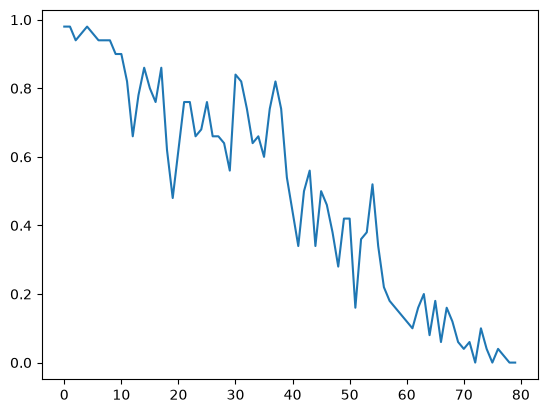

In [12]:
plt.plot(history["acceptanceHistory"])
# s

In [13]:
floor = []
sim_res = []
for k in range(1, len(UNIVERSE), 25):
    print(k)
    floor.append(calc_floor_performance(MARKET_CAPS, SIGMA_AUG, k))

    sim_res.append(RunSimulatedAnnealing(
        N,
        SIGMA_AUG,
        n_steps=N_STEPS,
        K=k,
        T_init=T_init,
        alpha=ALPHA,
    ))


1
26
51
76
101
126
151
176


In [15]:
floor

[np.float64(0.0004694259682957156),
 np.float64(3.752920109177371e-05),
 np.float64(2.7532181066249064e-05),
 np.float64(2.578312660900069e-05),
 np.float64(2.3863071820721413e-05),
 np.float64(2.3868013644409867e-05),
 np.float64(2.3977311596194957e-05),
 np.float64(2.3891109505598578e-05)]

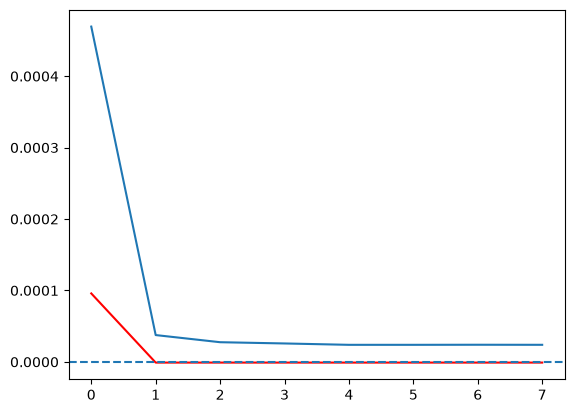

In [16]:
K = [1, 26, 51, 76, 101, 126, 151, 176]
plt.plot(floor)
plt.plot([n[1] - (i+1) * 1e-6 for i, n in zip(K, sim_res)], color='red')
plt.axhline(y=optimal_performance, linestyle='--')
# plt.xlim(left=1)